# Car Price Prediction with Machine Learning

## Oasis Infobyte Data Science Internship - Task 3

In [117]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [118]:

df = pd.read_csv("Car details v3.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset Loaded Successfully!
Dataset Shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [119]:

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Dataset Shape:
(8128, 13)

Column Names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), in

In [120]:

print("Missing Values in Each Column:")
print(df.isnull().sum())


Missing Values in Each Column:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64


In [121]:

print("Total Duplicate Rows:")
print(df.duplicated().sum())


Total Duplicate Rows:
1202


In [122]:

df.drop_duplicates(inplace=True)

print("Duplicates Removed Successfully!")
print("New Dataset Shape:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())


Duplicates Removed Successfully!
New Dataset Shape: (6926, 13)
Remaining Duplicates: 0


In [123]:

categorical_columns = ['fuel', 'seller_type', 'transmission', 'owner']

for col in categorical_columns:
    df[col] = df[col].str.strip().str.title()

print("Categorical Values Cleaned Successfully!")

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].unique())


Categorical Values Cleaned Successfully!

fuel:
['Diesel' 'Petrol' 'Lpg' 'Cng']

seller_type:
['Individual' 'Dealer' 'Trustmark Dealer']

transmission:
['Manual' 'Automatic']

owner:
['First Owner' 'Second Owner' 'Third Owner' 'Fourth & Above Owner'
 'Test Drive Car']


In [124]:

df['brand'] = df['name'].str.split().str[0]

print("Car Brand Extracted Successfully!")

print(df[['name', 'brand']].head(10))


Car Brand Extracted Successfully!
                                   name    brand
0                Maruti Swift Dzire VDI   Maruti
1          Skoda Rapid 1.5 TDI Ambition    Skoda
2              Honda City 2017-2020 EXi    Honda
3             Hyundai i20 Sportz Diesel  Hyundai
4                Maruti Swift VXI BSIII   Maruti
5         Hyundai Xcent 1.2 VTVT E Plus  Hyundai
6          Maruti Wagon R LXI DUO BSIII   Maruti
7                    Maruti 800 DX BSII   Maruti
8                      Toyota Etios VXD   Toyota
9  Ford Figo Diesel Celebration Edition     Ford


In [125]:

current_year = 2026

df['car_age'] = current_year - df['year']

print("Car Age Calculated Successfully!")

print(df[['name', 'year', 'car_age']].head(10))


Car Age Calculated Successfully!
                                   name  year  car_age
0                Maruti Swift Dzire VDI  2014       12
1          Skoda Rapid 1.5 TDI Ambition  2014       12
2              Honda City 2017-2020 EXi  2006       20
3             Hyundai i20 Sportz Diesel  2010       16
4                Maruti Swift VXI BSIII  2007       19
5         Hyundai Xcent 1.2 VTVT E Plus  2017        9
6          Maruti Wagon R LXI DUO BSIII  2007       19
7                    Maruti 800 DX BSII  2001       25
8                      Toyota Etios VXD  2011       15
9  Ford Figo Diesel Celebration Edition  2013       13


In [126]:

# Convert columns into numerical values

df['mileage'] = df['mileage'].str.replace(' kmpl', '', regex=False).str.replace(' km/kg', '', regex=False)

df['engine'] = df['engine'].str.replace(' CC', '', regex=False)

df['max_power'] = df['max_power'].str.replace(' bhp', '', regex=False)

df['mileage'] = pd.to_numeric(df['mileage'], errors='coerce')
df['engine'] = pd.to_numeric(df['engine'], errors='coerce')
df['max_power'] = pd.to_numeric(df['max_power'], errors='coerce')

print("Numerical Columns Converted Successfully!")

print(df[['mileage', 'engine', 'max_power', 'seats']].dtypes)


Numerical Columns Converted Successfully!
mileage      float64
engine       float64
max_power    float64
seats        float64
dtype: object


In [127]:

# Fill missing values using median

numerical_columns = ['mileage', 'engine', 'max_power', 'seats']

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

print("Missing Values Handled Successfully!")

print("\nRemaining Missing Values:")
print(df[numerical_columns].isnull().sum())


Missing Values Handled Successfully!

Remaining Missing Values:
mileage      0
engine       0
max_power    0
seats        0
dtype: int64


In [128]:

print("Torque Column Examples:")
print(df['torque'].head(15))

print("\nUnique Torque Values:")
print(df['torque'].nunique())


Torque Column Examples:
0               190Nm@ 2000rpm
1          250Nm@ 1500-2500rpm
2        12.7@ 2,700(kgm@ rpm)
3     22.4 kgm at 1750-2750rpm
4        11.5@ 4,500(kgm@ rpm)
5            113.75nm@ 4000rpm
6         7.8@ 4,500(kgm@ rpm)
7                59Nm@ 2500rpm
8          170Nm@ 1800-2400rpm
9               160Nm@ 2000rpm
10              248Nm@ 2250rpm
11               78Nm@ 4500rpm
12              190Nm@ 2000rpm
13                         NaN
14               84Nm@ 3500rpm
Name: torque, dtype: object

Unique Torque Values:
441


In [129]:

df.drop(columns=['torque'], inplace=True)

print("Torque Column Removed Successfully!")

print("Updated Dataset Shape:", df.shape)

print("Remaining Missing Values:")
print(df.isnull().sum())


Torque Column Removed Successfully!
Updated Dataset Shape: (6926, 14)
Remaining Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
seats            0
brand            0
car_age          0
dtype: int64


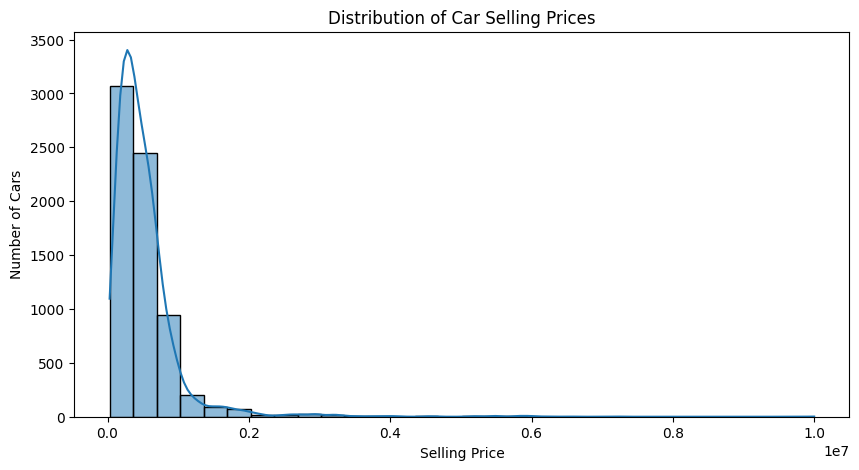

In [130]:

plt.figure(figsize=(10, 5))

sns.histplot(df['selling_price'], bins=30, kde=True)

plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price')
plt.ylabel('Number of Cars')

plt.show()


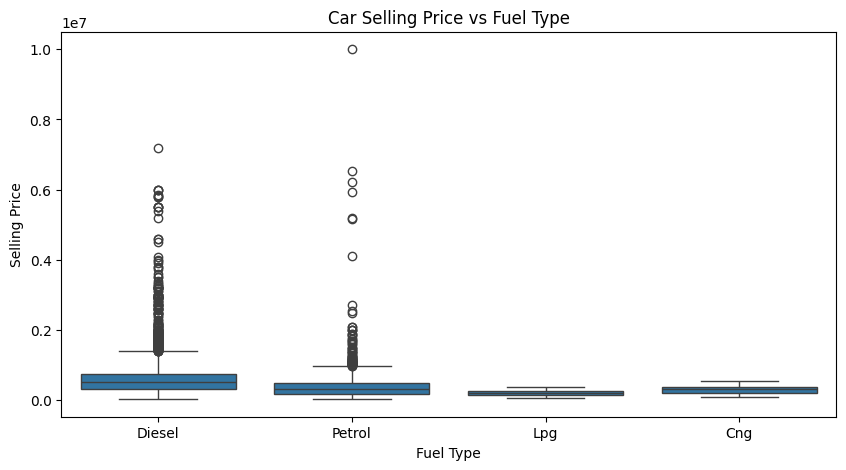

In [131]:

plt.figure(figsize=(10, 5))

sns.boxplot(x='fuel', y='selling_price', data=df)

plt.title('Car Selling Price vs Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price')

plt.show()


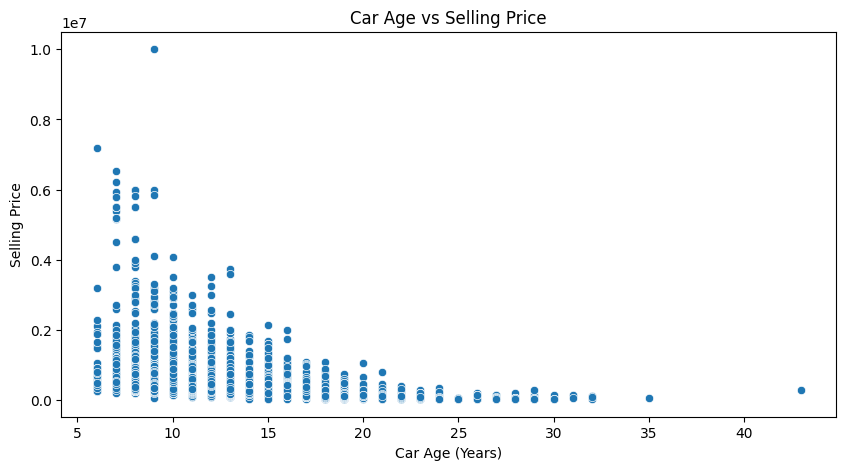

In [132]:

plt.figure(figsize=(10, 5))

sns.scatterplot(x='car_age', y='selling_price', data=df)

plt.title('Car Age vs Selling Price')
plt.xlabel('Car Age (Years)')
plt.ylabel('Selling Price')

plt.show()


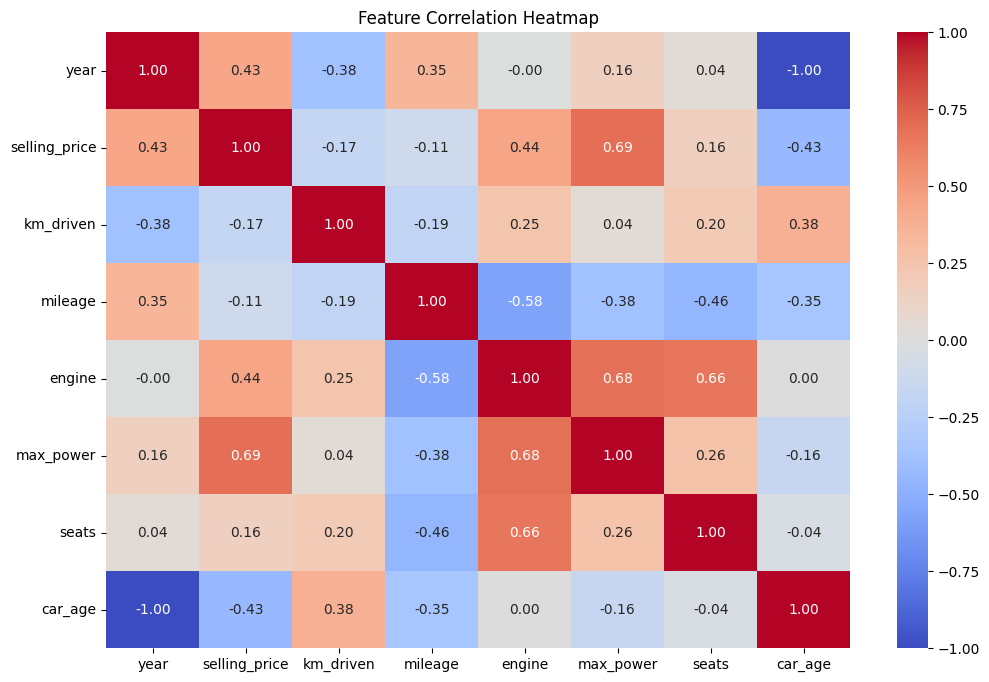

In [133]:

plt.figure(figsize=(12, 8))

numerical_df = df.select_dtypes(include=['number'])

sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Feature Correlation Heatmap')

plt.show()


In [134]:

X = df.drop(columns=['selling_price', 'name', 'year'])

y = df['selling_price']

print("Features and Target Selected Successfully!")

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())


Features and Target Selected Successfully!
Features Shape: (6926, 11)
Target Shape: (6926,)

Feature Columns:
['km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'seats', 'brand', 'car_age']


In [135]:

X = pd.get_dummies(
    X,
    columns=['fuel', 'seller_type', 'transmission', 'owner', 'brand'],
    drop_first=True
)

print("Categorical Encoding Completed!")

print("Updated Features Shape:", X.shape)

print("\nFirst 5 Rows:")
X.head()


Categorical Encoding Completed!
Updated Features Shape: (6926, 47)

First 5 Rows:


,km_driven,mileage,engine,max_power,seats,car_age,fuel_Diesel,fuel_Lpg,fuel_Petrol,seller_type_Individual,...,brand_Mitsubishi,brand_Nissan,brand_Opel,brand_Peugeot,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo
0,145500,23.40,1248.0,74.00,5.0,12,True,False,False,True,...,False,False,False,False,False,False,False,False,False,False
1,120000,21.14,1498.0,103.52,5.0,12,True,False,False,True,...,False,False,False,False,False,True,False,False,False,False
2,140000,17.70,1497.0,78.00,5.0,20,False,False,True,True,...,False,False,False,False,False,False,False,False,False,False
3,127000,23.00,1396.0,90.00,5.0,16,True,False,False,True,...,False,False,False,False,False,False,False,False,False,False
4,120000,16.10,1298.0,88.20,5.0,19,False,False,True,True,...,False,False,False,False,False,False,False,False,False,False


In [136]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train-Test Split Completed!")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Train-Test Split Completed!
Training Features: (5540, 47)
Testing Features: (1386, 47)
Training Target: (5540,)
Testing Target: (1386,)


In [137]:

from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [138]:

import sys
print("Python Version:", sys.version)
print("Python Executable:", sys.executable)

import sklearn
print("Scikit-learn Version:", sklearn.__version__)


Python Version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Python Executable: c:\Users\HP\AppData\Local\Python\pythoncore-3.11-64\python.exe
Scikit-learn Version: 1.4.1.post1


In [139]:
y_pred_lr = lr_model.predict(X_test)

In [140]:


from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_lr)

rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))

r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Model Evaluation")
print("----------------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)


Linear Regression Model Evaluation
----------------------------------
MAE: 133098.5333513055
RMSE: 262236.18655532633
R2 Score: 0.6864521836315063


In [141]:

from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train, y_train)

print("Ridge Regression Model Trained Successfully!")



Ridge Regression Model Trained Successfully!


In [142]:

y_pred_ridge = ridge_model.predict(X_test)

print("Ridge Regression Predictions Generated!")

print("\nFirst 10 Actual Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Prices:")
print(y_pred_ridge[:10])


Ridge Regression Predictions Generated!

First 10 Actual Prices:
[ 550000 1225000  850000   80000  825000  800000  229999   93150  300000
  493000]

First 10 Predicted Prices:
[ 619781.48533158 1050499.29268462  727808.84335886   58585.59250816
  762581.29421664  776517.32878132  299213.53419913   19902.85021493
  233995.38932574  440315.28059545]


In [143]:

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)

rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Model Evaluation")
print("--------------------------------")
print("MAE:", mae_ridge)
print("RMSE:", rmse_ridge)
print("R2 Score:", r2_ridge)


Ridge Regression Model Evaluation
--------------------------------
MAE: 133529.41051415834
RMSE: 258925.41504856586
R2 Score: 0.6943193830354596


In [144]:

comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression'],
    'MAE': [mae, mae_ridge],
    'RMSE': [rmse, rmse_ridge],
    'R2 Score': [r2, r2_ridge]
})

comparison


,Model,MAE,RMSE,R2 Score
0,Linear Regression,133098.533351,262236.186555,0.686452
1,Ridge Regression,133529.410514,258925.415049,0.694319


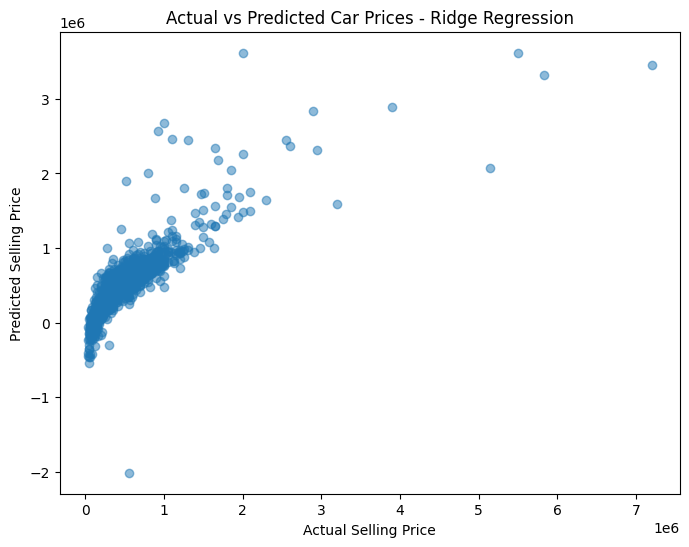

In [145]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_ridge, alpha=0.5)

plt.xlabel('Actual Selling Price')
plt.ylabel('Predicted Selling Price')
plt.title('Actual vs Predicted Car Prices - Ridge Regression')

plt.show()


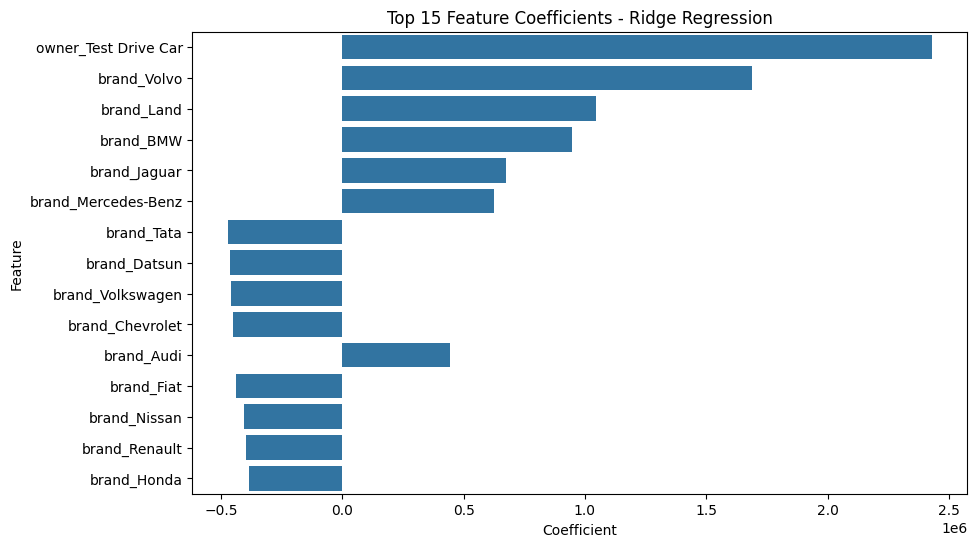

In [146]:

coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': ridge_model.coef_
})

coefficients['Absolute Coefficient'] = coefficients['Coefficient'].abs()

top_features = coefficients.sort_values(
    by='Absolute Coefficient',
    ascending=False
).head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    x='Coefficient',
    y='Feature',
    data=top_features
)

plt.title('Top 15 Feature Coefficients - Ridge Regression')
plt.xlabel('Coefficient')
plt.ylabel('Feature')

plt.show()


In [147]:

from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth=12,
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree Model trained successfully!")


Decision Tree Model trained successfully!


In [148]:

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree predictions completed!")
print("First 5 predictions:", y_pred_dt[:5])


Decision Tree predictions completed!
First 5 predictions: [ 494642.78571429 1055199.9         829418.58139535  155187.47916667
  595571.42857143]


In [149]:

mae_dt = mean_absolute_error(y_test, y_pred_dt)

rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))

r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Model Performance")
print("MAE:", mae_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)


Decision Tree Model Performance
MAE: 86782.97937194518
RMSE: 158723.11549622085
R2 Score: 0.885132042728513


In [150]:

comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Ridge Regression',
        'Decision Tree'
    ],
    'MAE': [mae, mae_ridge, mae_dt],
    'RMSE': [rmse, rmse_ridge, rmse_dt],
    'R2 Score': [r2, r2_ridge, r2_dt]
})

comparison.sort_values(by='R2 Score', ascending=False)


,Model,MAE,RMSE,R2 Score
2,Decision Tree,86782.979372,158723.115496,0.885132
1,Ridge Regression,133529.410514,258925.415049,0.694319
0,Linear Regression,133098.533351,262236.186555,0.686452


In [151]:

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': dt_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(10)


,Feature,Importance
3,max_power,0.623023
5,car_age,0.235820
1,mileage,0.064377
2,engine,0.021857
0,km_driven,0.016410
31,brand_Land,0.005832
43,brand_Tata,0.005530
36,brand_Mercedes-Benz,0.005028
44,brand_Toyota,0.004539
6,fuel_Diesel,0.002583


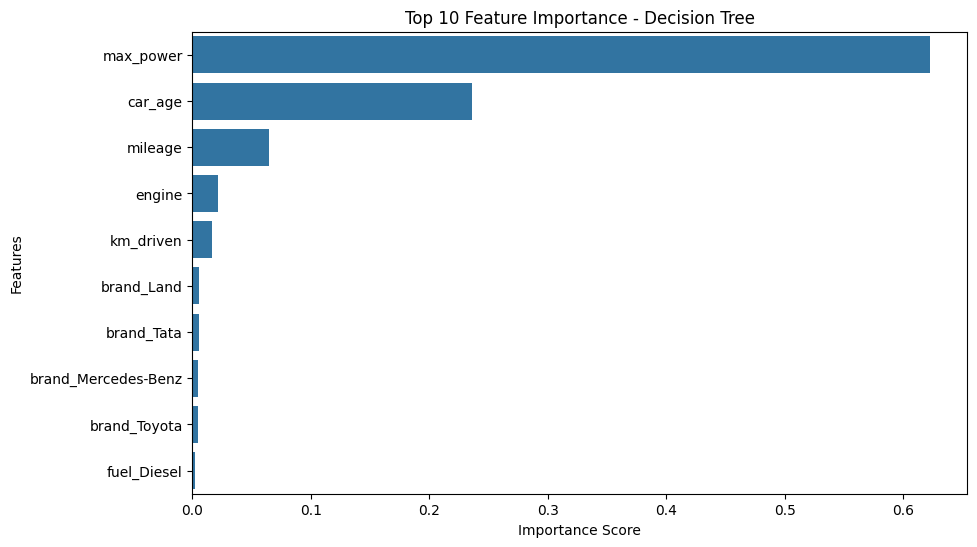

In [152]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Feature Importance - Decision Tree')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.show()


## Final Conclusion

In this project, we developed a machine learning model to predict used car selling prices using Python.

We performed data cleaning, exploratory data analysis, feature engineering, categorical encoding, and model training.

Three regression models were evaluated:
1. Linear Regression
2. Ridge Regression
3. Decision Tree Regressor

Among these models, **Decision Tree Regressor performed the best**, achieving an R² score of 88.51%, MAE of ₹86,782.98, and RMSE of ₹1,58,723.12.

Feature importance analysis showed that max_power, car_age, and mileage were among the most influential features.

Therefore, Decision Tree Regressor was selected as the final model for used car price prediction.